In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [2]:
df = pd.read_csv("emails.csv")
df.head()

,Email No.,the,to,ect,and,for,of,a,you,hou,...,connevey,jay,valued,lay,infrastructure,military,allowing,ff,dry,Prediction
0,Email 1,0,0,1,0,0,0,2,0,0,...,0,0,0,0,0,0,0,0,0,0
1,Email 2,8,13,24,6,6,2,102,1,27,...,0,0,0,0,0,0,0,1,0,0
2,Email 3,0,0,1,0,0,0,8,0,0,...,0,0,0,0,0,0,0,0,0,0
3,Email 4,0,5,22,0,5,1,51,2,10,...,0,0,0,0,0,0,0,0,0,0
4,Email 5,7,6,17,1,5,2,57,0,9,...,0,0,0,0,0,0,0,1,0,0


In [3]:
print("Dataset Shape:", df.shape)
print(df.info())
print(df.describe())

Dataset Shape: (5172, 3002)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5172 entries, 0 to 5171
Columns: 3002 entries, Email No. to Prediction
dtypes: int64(3001), object(1)
memory usage: 118.5+ MB
None
               the           to          ect          and          for  \
count  5172.000000  5172.000000  5172.000000  5172.000000  5172.000000   
mean      6.640565     6.188128     5.143852     3.075599     3.124710   
std      11.745009     9.534576    14.101142     6.045970     4.680522   
min       0.000000     0.000000     1.000000     0.000000     0.000000   
25%       0.000000     1.000000     1.000000     0.000000     1.000000   
50%       3.000000     3.000000     1.000000     1.000000     2.000000   
75%       8.000000     7.000000     4.000000     3.000000     4.000000   
max     210.000000   132.000000   344.000000    89.000000    47.000000   

                of            a          you          hou           in  ...  \
count  5172.000000  5172.000000  5172.000000 

In [4]:
print("Missing Values:", df.isnull().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())
print("Target Distribution:")
print(df['Prediction'].value_counts())

Missing Values: 0
Duplicate Rows: 0
Target Distribution:
Prediction
0    3672
1    1500
Name: count, dtype: int64


In [5]:
df = df.dropna()
df = df.drop_duplicates()

X = df.drop(['Email No.', 'Prediction'], axis=1)
y = df['Prediction']

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (5172, 3000)
Target Shape: (5172,)


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (4137, 3000)
Testing Data: (1035, 3000)


In [7]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [8]:
knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train, y_train)

y_pred_knn = knn.predict(X_test)

print("KNN Accuracy:", accuracy_score(y_test, y_pred_knn))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_knn))

KNN Accuracy: 0.8338164251207729

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.78      0.87       735
           1       0.64      0.96      0.77       300

    accuracy                           0.83      1035
   macro avg       0.81      0.87      0.82      1035
weighted avg       0.88      0.83      0.84      1035



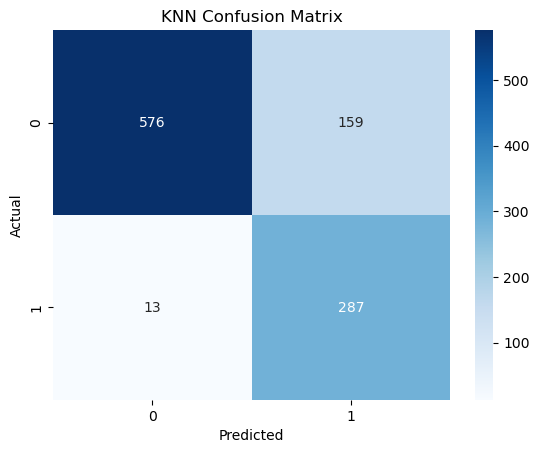

In [9]:
cm_knn = confusion_matrix(y_test, y_pred_knn)

sns.heatmap(cm_knn, annot=True, fmt='d', cmap='Blues')

plt.title("KNN Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [10]:
svm = SVC(kernel='linear')

svm.fit(X_train, y_train)

y_pred_svm = svm.predict(X_test)

print("SVM Accuracy:", accuracy_score(y_test, y_pred_svm))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_svm))

SVM Accuracy: 0.9507246376811594

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.96      0.97       735
           1       0.91      0.92      0.92       300

    accuracy                           0.95      1035
   macro avg       0.94      0.94      0.94      1035
weighted avg       0.95      0.95      0.95      1035



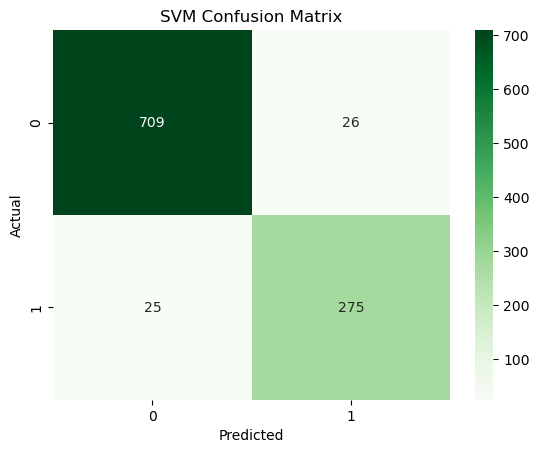

In [11]:
cm_svm = confusion_matrix(y_test, y_pred_svm)

sns.heatmap(cm_svm, annot=True, fmt='d', cmap='Greens')

plt.title("SVM Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [12]:
results = pd.DataFrame({
    'Algorithm': ['KNN', 'SVM'],
    'Accuracy': [
        accuracy_score(y_test, y_pred_knn),
        accuracy_score(y_test, y_pred_svm)
    ]
})

print(results)

  Algorithm  Accuracy
0       KNN  0.833816
1       SVM  0.950725


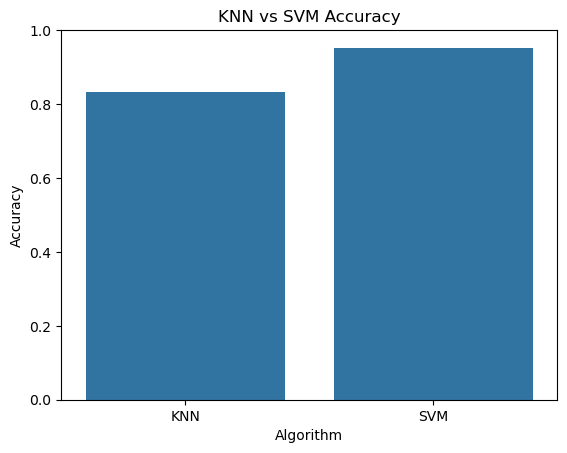

In [13]:
sns.barplot(data=results, x='Algorithm', y='Accuracy')

plt.title("KNN vs SVM Accuracy")
plt.ylim(0, 1)
plt.show()

In [15]:

# THEORY: EMAIL SPAM CLASSIFICATION USING KNN AND SVM
#
# 1. INTRODUCTION
#
# Email Spam Classification is a supervised Machine Learning
# classification problem used to identify whether an email is
# spam or ham (not spam).
#
# Spam emails are unwanted messages that may contain advertisements,
# fraudulent links or irrelevant information.
# Ham emails are genuine and useful messages.
#
# Machine Learning algorithms can learn patterns from previously
# classified emails and use those patterns to classify new emails.
#
# In this practical, two classification algorithms are implemented:
# K-Nearest Neighbors (KNN) and Support Vector Machine (SVM).
# Their performance is analyzed and compared using accuracy,
# classification reports and confusion matrices.
#
#
# 2. DATASET DESCRIPTION
#
# The emails.csv dataset contains email-related numerical features.
# It consists of 5172 records and 3002 columns.
#
# Important columns include:
#
# 1. Email No.: Unique identifier for each email.
# 2. Numerical word-frequency features: Represent the frequency
#    or occurrence of different words in an email.
# 3. Prediction: Target variable representing the email category.
#
# The Prediction column contains two classes:
# 0 - Ham (Not Spam)
# 1 - Spam
#
# The Email No. column is removed because it is only an identifier
# and does not contribute useful information for classification.
#
# The numerical word-frequency features are used as input variables,
# while Prediction is used as the target variable.
#
#
# 3. DATA PREPROCESSING
#
# Data preprocessing is the process of cleaning and preparing
# raw data before applying Machine Learning algorithms.
#
# First, the dataset is loaded using the Pandas library.
# Missing values and duplicate records are checked.
#
# Missing records and duplicate records are removed where necessary.
#
# The Email No. column is dropped because it does not contain
# meaningful information for predicting whether an email is spam.
#
# The remaining numerical features are stored in X, while the
# Prediction column is stored in y.
#
# Since the dataset already contains numerical word-frequency
# features, additional text vectorization is not required.
#
#
# 4. TRAIN-TEST SPLITTING
#
# The dataset is divided into training and testing sets using
# the train_test_split() function.
#
# 80% of the data is used for training the Machine Learning models,
# while 20% is used for testing their performance.
#
# The stratify parameter is used to maintain the proportion of
# spam and ham classes in both training and testing datasets.
#
# This helps evaluate the models on unseen data.
#
#
# 5. FEATURE SCALING
#
# Feature scaling is the process of bringing numerical features
# to a similar scale.
#
# StandardScaler is used in this practical.
#
# The formula for standardization is:
#
# Z = (X - Mean) / Standard Deviation
#
# Where:
# X = Original feature value
# Mean = Mean of the feature
# Standard Deviation = Standard deviation of the feature
#
# After standardization, features generally have a mean of 0
# and a standard deviation of 1.
#
# Scaling is important for KNN because it calculates distances
# between data points.
#
# It is also useful for SVM because feature magnitudes can affect
# the position of the separating hyperplane.
#
# The scaler is fitted only on the training data and then used
# to transform both training and testing data.
#
#
# 6. K-NEAREST NEIGHBORS (KNN)
#
# K-Nearest Neighbors is a supervised Machine Learning algorithm
# used for classification and regression.
#
# It is a distance-based algorithm that classifies a new data
# point by examining its K nearest training data points.
#
# The steps involved are:
#
# 1. Select the value of K.
# 2. Calculate the distance between the new data point and
#    the training data points.
# 3. Identify the K nearest neighbors.
# 4. Count the class labels of the selected neighbors.
# 5. Assign the majority class to the new data point.
#
# The Euclidean distance formula is:
#
# d = sqrt(SUM((Xi - Yi)^2))
#
# Where Xi and Yi represent feature values of two data points.
#
# In this practical, KNN is implemented using KNeighborsClassifier
# with K = 5.
#
# The model predicts whether an email is spam or ham based on
# the classes of its nearest neighbors.
#
#
# 7. SUPPORT VECTOR MACHINE (SVM)
#
# Support Vector Machine is a supervised Machine Learning
# algorithm mainly used for classification problems.
#
# SVM separates different classes by finding an optimal
# decision boundary called a hyperplane.
#
# The main objective is to maximize the margin between the
# hyperplane and the nearest data points of different classes.
#
# The nearest data points that influence the decision boundary
# are called support vectors.
#
# A larger margin generally helps the model generalize better
# to unseen data.
#
# SVM can handle high-dimensional datasets and different types
# of classification problems.
#
# In this practical, SVM is implemented using SVC with a linear
# kernel.
#
# The linear kernel is suitable for finding a linear decision
# boundary between spam and ham emails.
#
#
# 8. MODEL PREDICTION
#
# Both KNN and SVM models are trained using the training dataset.
#
# After training, the models predict the classes of emails
# in the testing dataset.
#
# The predicted values are compared with the actual values
# to evaluate classification performance.
#
#
# 9. MODEL EVALUATION
#
# The performance of the classification algorithms is evaluated
# using accuracy, classification report and confusion matrix.
#
# A. ACCURACY
#
# Accuracy measures the proportion of correctly classified
# predictions out of all predictions.
#
# Accuracy = (TP + TN) / (TP + TN + FP + FN)
#
# B. CONFUSION MATRIX
#
# A confusion matrix is used to evaluate the performance
# of a classification model.
#
# It contains four important values:
#
# TP (True Positive): Spam emails correctly classified as spam.
# TN (True Negative): Ham emails correctly classified as ham.
# FP (False Positive): Ham emails incorrectly classified as spam.
# FN (False Negative): Spam emails incorrectly classified as ham.
#
# C. PRECISION
#
# Precision measures how many emails predicted as spam
# are actually spam.
#
# Precision = TP / (TP + FP)
#
# D. RECALL
#
# Recall measures how many actual spam emails are correctly
# identified by the model.
#
# Recall = TP / (TP + FN)
#
# E. F1-SCORE
#
# F1-score is the harmonic mean of precision and recall.
#
# F1-Score = 2 * (Precision * Recall) / (Precision + Recall)
#
# A classification report provides precision, recall, F1-score
# and support for each class.
#
#
# 10. COMPARISON OF KNN AND SVM
#
# KNN classifies emails based on the majority class of their
# nearest neighbors, whereas SVM classifies emails using
# an optimal separating hyperplane.
#
# KNN is simple and easy to understand but prediction can be
# computationally expensive for large datasets.
#
# SVM can perform well on high-dimensional data, but its
# training time and performance depend on the dataset and kernel.
#
# Both models are evaluated using the same testing dataset.
# Their accuracy scores are compared using a table and graph.
#
# The model with better evaluation performance can be selected
# for email spam classification.
#
#
# 11. CONCLUSION
#
# In this practical, email spam classification is performed
# using supervised Machine Learning algorithms.
#
# The dataset is loaded, inspected and preprocessed.
# Numerical features are standardized using StandardScaler.
#
# KNN and SVM classifiers are trained and used to predict
# whether emails belong to the spam or ham category.
#
# Their performance is evaluated using accuracy, classification
# reports and confusion matrices.
#
# Finally, both classifiers are compared to identify the
# more suitable model for email spam classification.
